In [ ]:
!pip install yfinance

In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

tickers = ['AAPL', 'MSFT', 'TSLA']

stock_data = {}

for ticker in tickers:
    df = yf.download(ticker, period='2y', auto_adjust=True, progress=False)

    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    stock_data[ticker] = df

print("Data downloaded successfully!")

Data downloaded successfully!


In [ ]:
for ticker in tickers:
    print("\n==========", ticker, "==========")
    print(stock_data[ticker].head())
    stock_data[ticker].info()


========== AAPL ==========
Price            Close        High         Low        Open    Volume
Date                                                                
2024-11-21  226.701324  228.328272  223.913690  227.058460  42108300
2024-11-22  228.040558  228.883799  226.244965  226.244965  38168300
2024-11-25  231.016708  231.393689  227.911629  229.617941  90152800
2024-11-26  233.189270  233.695221  231.473042  231.473042  45986200
2024-11-27  233.060303  233.814264  231.949221  232.603972  33498400
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 501 entries, 2024-11-21 to 2026-11-20
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   501 non-null    float64
 1   High    501 non-null    float64
 2   Low     501 non-null    float64
 3   Open    501 non-null    float64
 4   Volume  501 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 23.5 KB

========== MSFT ==========
Price            Close      

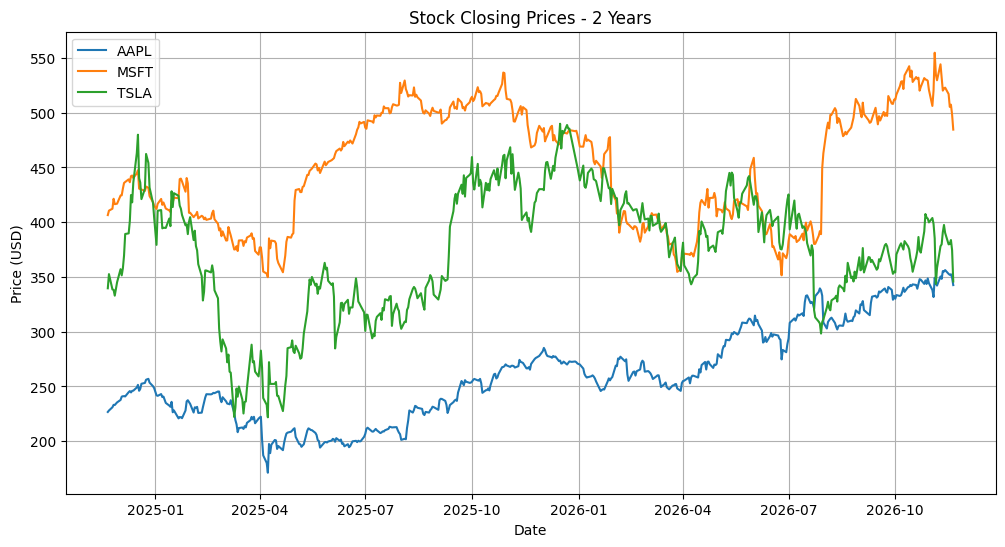

In [ ]:
plt.figure(figsize=(12,6))

for ticker in tickers:
    plt.plot(stock_data[ticker].index,
             stock_data[ticker]['Close'],
             label=ticker)

plt.title('Stock Closing Prices - 2 Years')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
returns = pd.DataFrame()

for ticker in tickers:
    returns[ticker] = stock_data[ticker]['Close'].pct_change()

print(returns.head())

                AAPL      MSFT      TSLA
Date                                    
2024-11-21       NaN       NaN       NaN
2024-11-22  0.005907  0.010003  0.038040
2024-11-25  0.013051  0.004293 -0.039624
2024-11-26  0.009404  0.021968 -0.001063
2024-11-27 -0.000553 -0.011683 -0.015788


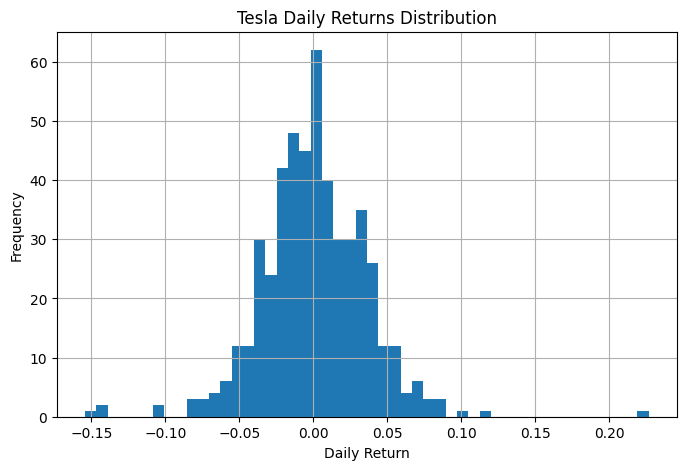

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(returns['TSLA'].dropna(), bins=50)

plt.title('Tesla Daily Returns Distribution')
plt.xlabel('Daily Return')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

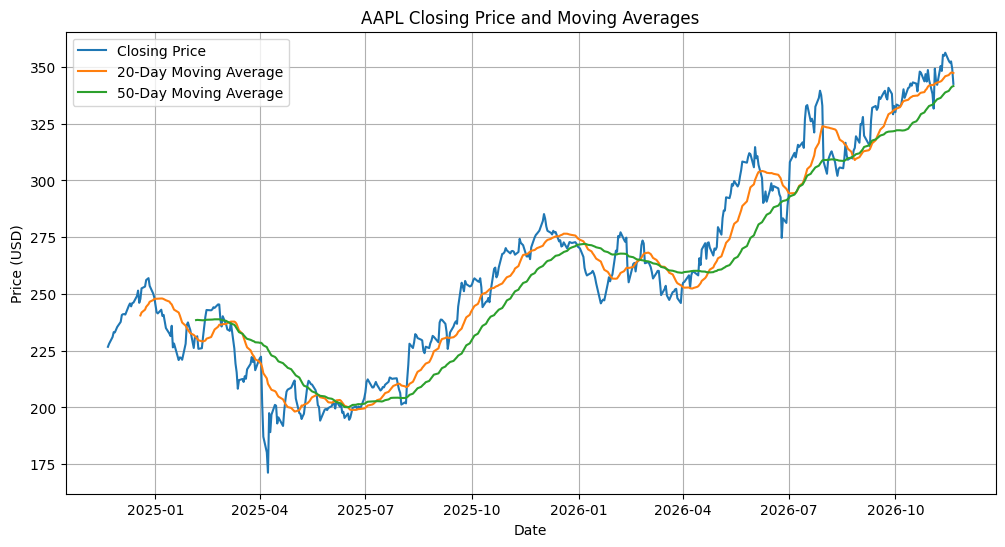

In [ ]:
ticker = 'AAPL'

close = stock_data[ticker]['Close']

ma20 = close.rolling(window=20).mean()
ma50 = close.rolling(window=50).mean()

plt.figure(figsize=(12,6))

plt.plot(close, label='Closing Price')
plt.plot(ma20, label='20-Day Moving Average')
plt.plot(ma50, label='50-Day Moving Average')

plt.title('AAPL Closing Price and Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
volatility = returns.std()

volatility_table = pd.DataFrame({
    'Ticker': volatility.index,
    'Daily Volatility': volatility.values
})

print(volatility_table)

  Ticker  Daily Volatility
0   AAPL          0.018290
1   MSFT          0.018656
2   TSLA          0.035626


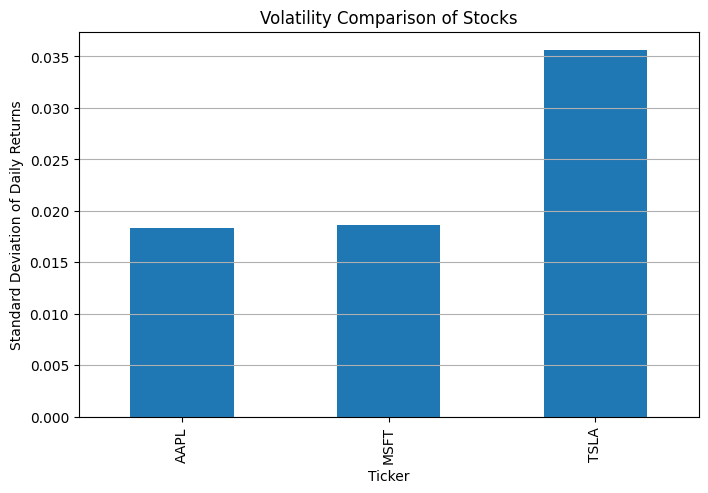

In [ ]:
volatility_table.plot(
    x='Ticker',
    y='Daily Volatility',
    kind='bar',
    figsize=(8,5),
    legend=False
)

plt.title('Volatility Comparison of Stocks')
plt.ylabel('Standard Deviation of Daily Returns')
plt.grid(axis='y')
plt.show()

## Conclusion

In this project, I analyzed two years of historical stock price data for Apple (AAPL), Microsoft (MSFT), and Tesla (TSLA) using Python, yfinance, and pandas. I calculated daily returns and used 20-day and 50-day moving averages to observe price trends. Based on the daily return standard deviation, Tesla (TSLA) showed the highest volatility at 3.563%, followed by Microsoft (MSFT) at 1.866% and Apple (AAPL) at 1.829%. This project helped me understand time-series data, stock price trends, and volatility visualization using Matplotlib.

*This analysis is for educational purposes only and is not financial advice.*